In [45]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/processed/clean_apartments.csv")

print(df.shape)
df.head()

(3584, 9)


,street_type,street_name,neighborhood,area_sqm,price_lei,year_built,transaction_period,price_per_sqm,transaction_quarter
0,Alee,BISTRICIOARA,colentina,91.41,469908.0,1989.0,2022-T1,5140.662947,1
1,Alee,BISTRICIOARA,colentina,56.44,252241.0,1987.0,2022-T1,4469.188519,1
2,Alee,BRASOVENI,tei,52.40,373347.0,1985.0,2022-T1,7124.942748,1
3,Alee,BURIDAVA,colentina,43.56,316527.0,2016.0,2022-T1,7266.460055,1
4,Alee,CIRCULUI,tei,59.60,495000.0,1960.0,2022-T1,8305.369128,1


In [46]:
X = df.drop(columns=[
    "price_lei",
    "price_per_sqm",
    "transaction_period"
])

y = df["price_lei"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X.head()

X shape: (3584, 6)
y shape: (3584,)


,street_type,street_name,neighborhood,area_sqm,year_built,transaction_quarter
0,Alee,BISTRICIOARA,colentina,91.41,1989.0,1
1,Alee,BISTRICIOARA,colentina,56.44,1987.0,1
2,Alee,BRASOVENI,tei,52.40,1985.0,1
3,Alee,BURIDAVA,colentina,43.56,2016.0,1
4,Alee,CIRCULUI,tei,59.60,1960.0,1


In [47]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (2867, 6)
X_test: (717, 6)
y_train: (2867,)
y_test: (717,)


In [48]:
numeric_features = [
    "area_sqm",
    "year_built",
    "transaction_quarter"
]

categorical_features = [
    "street_type",
    "neighborhood"
]

In [49]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [50]:
from sklearn.linear_model import LinearRegression

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['street_type','street_name','neighborhood','area_sqm','year_built', 'transaction_quarter']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. 

In [51]:
y_pred = model.predict(X_test)

print("First 5 predictions:")
print(y_pred[:5])

print("\nFirst 5 actual prices:")
print(y_test.iloc[:5].values)

First 5 predictions:
[375823.15522073 351840.16780939 452779.02357085 341044.09811074
 471348.29984745]

First 5 actual prices:
[311717. 346000. 542521. 311528. 438363.]


In [52]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

r2 = r2_score(y_test, y_pred)

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R²:", round(r2, 3))

MAE: 98699.71
RMSE: 162135.67
R²: 0.654


In [53]:
from sklearn.dummy import DummyRegressor

dummy_model = DummyRegressor(strategy="mean")

dummy_model.fit(X_train, y_train)

dummy_pred = dummy_model.predict(X_test)

print("Dummy MAE:", round(mean_absolute_error(y_test, dummy_pred), 2))
print("Dummy RMSE:", round(np.sqrt(mean_squared_error(y_test, dummy_pred)), 2))
print("Dummy R²:", round(r2_score(y_test, dummy_pred), 3))

Dummy MAE: 181380.15
Dummy RMSE: 275560.82
Dummy R²: -0.0


In [54]:
from sklearn.ensemble import RandomForestRegressor

rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['street_type','street_name','neighborhood','area_sqm','year_built', 'transaction_quarter']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. 

In [55]:
rf_pred = rf_model.predict(X_test)

print("Random Forest MAE:", round(mean_absolute_error(y_test, rf_pred), 2))
print("Random Forest RMSE:", round(np.sqrt(mean_squared_error(y_test, rf_pred)), 2))
print("Random Forest R²:", round(r2_score(y_test, rf_pred), 3))

Random Forest MAE: 90030.34
Random Forest RMSE: 158441.02
Random Forest R²: 0.669


In [56]:
rf_train_pred = rf_model.predict(X_train)

print(
    "Train MAE:",
    round(mean_absolute_error(y_train, rf_train_pred), 2)
)

print(
    "Test MAE:",
    round(mean_absolute_error(y_test, rf_pred), 2)
)

Train MAE: 34425.39
Test MAE: 90030.34


In [57]:
rf_regularized = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        max_depth=12,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ))
])

rf_regularized.fit(X_train, y_train)

train_pred_reg = rf_regularized.predict(X_train)
test_pred_reg = rf_regularized.predict(X_test)

print("Train MAE:", round(mean_absolute_error(y_train, train_pred_reg), 2))
print("Test MAE:", round(mean_absolute_error(y_test, test_pred_reg), 2))

Train MAE: 70089.63
Test MAE: 90141.3


In [58]:
from xgboost import XGBRegressor

print("XGBoost installed successfully!")

XGBoost installed successfully!


In [59]:
xgb_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", XGBRegressor(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        random_state=42,
        n_jobs=-1
    ))
])

In [60]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    xgb_model,
    X_train,
    y_train,
    cv=5,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

cv_mae = -cv_scores

print("MAE pentru fiecare fold:", cv_mae.round(2))
print("Mean CV MAE:", round(cv_mae.mean(), 2))
print("CV Standard Deviation:", round(cv_mae.std(), 2))

MAE pentru fiecare fold: [78403.46 91956.91 87973.4  89673.74 98821.51]
Mean CV MAE: 89365.81
CV Standard Deviation: 6608.04


In [61]:
rf_cv_scores = cross_val_score(
    rf_regularized,
    X_train,
    y_train,
    cv=5,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

rf_cv_mae = -rf_cv_scores

print("Random Forest CV MAE:", rf_cv_mae.round(2))
print("Mean RF CV MAE:", round(rf_cv_mae.mean(), 2))
print("RF CV Standard Deviation:", round(rf_cv_mae.std(), 2))

Random Forest CV MAE: [ 83234.49  92994.35  86334.36  93508.68 103244.06]
Mean RF CV MAE: 91863.19
RF CV Standard Deviation: 6907.01


In [62]:
rf_original_cv = -cross_val_score(
    rf_model,
    X_train,
    y_train,
    cv=5,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

print("Original RF CV MAE:", rf_original_cv.round(2))
print("Mean CV MAE:", round(rf_original_cv.mean(), 2))
print("CV Standard Deviation:", round(rf_original_cv.std(), 2))

Original RF CV MAE: [ 83780.39  91456.53  86229.28  99192.77 100318.5 ]
Mean CV MAE: 92195.49
CV Standard Deviation: 6661.84


In [63]:
from sklearn.model_selection import RandomizedSearchCV

param_distributions = {
    "regressor__n_estimators": [100, 200, 300],
    "regressor__max_depth": [2, 3, 4, 5],
    "regressor__learning_rate": [0.03, 0.05, 0.1],
    "regressor__subsample": [0.8, 1.0],
    "regressor__colsample_bytree": [0.8, 1.0]
}

In [64]:
random_search = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=param_distributions,
    n_iter=15,
    cv=5,
    scoring="neg_mean_absolute_error",
    random_state=42,
    n_jobs=-1,
    verbose=1
)

In [65]:
random_search.fit(X_train, y_train)

print("Best parameters:")
print(random_search.best_params_)

print(
    "Best CV MAE:",
    round(-random_search.best_score_, 2)
)

Fitting 5 folds for each of 15 candidates, totalling 75 fits
Best parameters:
{'regressor__subsample': 0.8, 'regressor__n_estimators': 300, 'regressor__max_depth': 5, 'regressor__learning_rate': 0.03, 'regressor__colsample_bytree': 1.0}
Best CV MAE: 88139.33


In [66]:
best_xgb_model = random_search.best_estimator_

print("Best model saved in variable!")
print(best_xgb_model)

Best model saved in variable!
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['area_sqm', 'year_built',
                                                   'transaction_quarter']),
                                                 ('cat',
                                                  Pipeline(steps=[('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['street_type',
                                                   'neighborhood'])])),

In [67]:
import joblib
from pathlib import Path

model_path = Path("../models/best_xgb_model.joblib")

model_path.parent.mkdir(parents=True, exist_ok=True)

joblib.dump(best_xgb_model, model_path)

print("Model saved successfully!")

Model saved successfully!


In [68]:
loaded_model = joblib.load("../models/best_xgb_model.joblib")

original_predictions = best_xgb_model.predict(X_train.head(5))
loaded_predictions = loaded_model.predict(X_train.head(5))

print(
    "Predictions identical:",
    np.allclose(original_predictions, loaded_predictions)
)

Predictions identical: True


In [69]:
final_pred = loaded_model.predict(X_test)

final_mae = mean_absolute_error(y_test, final_pred)
final_rmse = np.sqrt(mean_squared_error(y_test, final_pred))
final_r2 = r2_score(y_test, final_pred)

print("Final XGBoost MAE:", round(final_mae, 2))
print("Final XGBoost RMSE:", round(final_rmse, 2))
print("Final XGBoost R²:", round(final_r2, 3))

Final XGBoost MAE: 91656.91
Final XGBoost RMSE: 161662.87
Final XGBoost R²: 0.656


In [70]:
import shap

print("SHAP version:", shap.__version__)

SHAP version: 0.53.0


In [71]:
xgb_preprocessor = loaded_model.named_steps["preprocessor"]
xgb_regressor = loaded_model.named_steps["regressor"]

print(type(xgb_preprocessor))
print(type(xgb_regressor))

<class 'sklearn.compose._column_transformer.ColumnTransformer'>
<class 'xgboost.sklearn.XGBRegressor'>


In [72]:
X_shap = X_train.sample(n=200, random_state=42)

X_shap_transformed = xgb_preprocessor.transform(X_shap)

feature_names = xgb_preprocessor.get_feature_names_out()

print("Shape:", X_shap_transformed.shape)
print("Number of features:", len(feature_names))
print("First 10 features:", feature_names[:10])

Shape: (200, 22)
Number of features: 22
First 10 features: ['num__area_sqm' 'num__year_built' 'num__transaction_quarter'
 'cat__street_type_Alee' 'cat__street_type_Bulevard'
 'cat__street_type_Calea' 'cat__street_type_Intrare'
 'cat__street_type_Piata' 'cat__street_type_Prelungire'
 'cat__street_type_Sosea']


In [73]:
explainer = shap.TreeExplainer(xgb_regressor)

shap_values = explainer(X_shap_transformed)

print("SHAP values shape:", shap_values.values.shape)
print("Base value:", shap_values.base_values[0])

SHAP values shape: (200, 22)
Base value: 435332.16


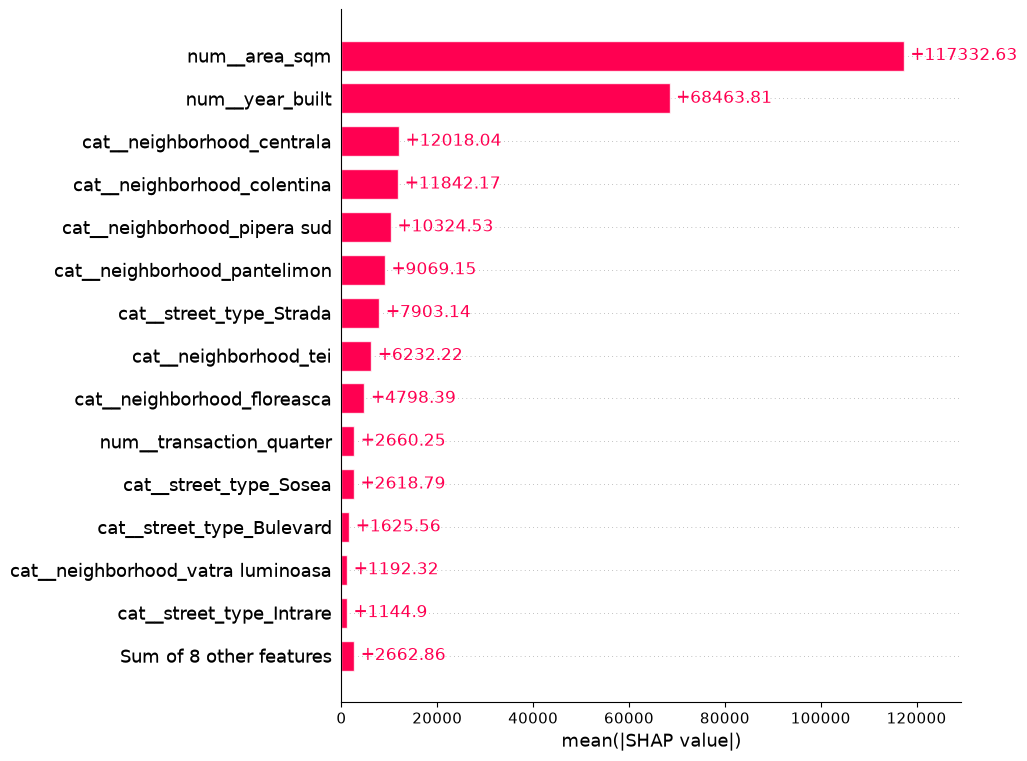

In [74]:
shap_values.feature_names = list(feature_names)

shap.plots.bar(shap_values, max_display=15)

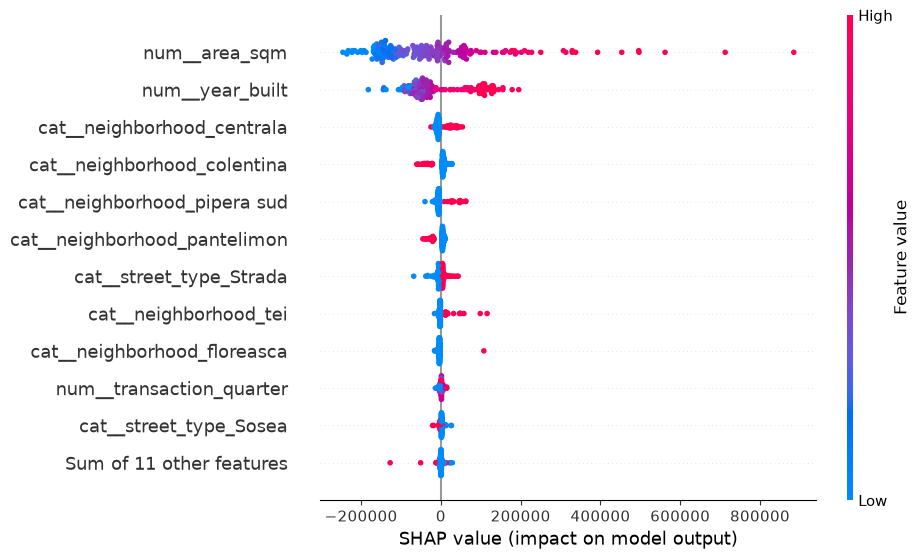

In [75]:
shap.plots.beeswarm(shap_values, max_display=12)

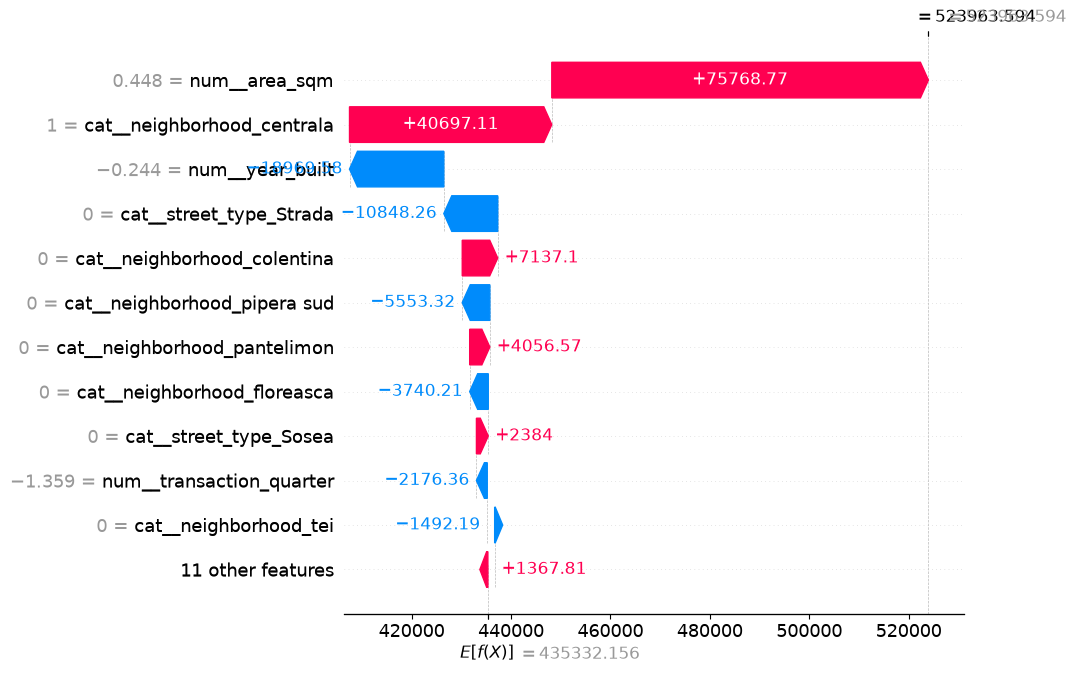

In [76]:
shap.plots.waterfall(shap_values[0], max_display=12)

In [77]:
from sklearn.base import clone
from sklearn.model_selection import train_test_split

X_fit, X_cal, y_fit, y_cal = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42
)

conformal_model = clone(best_xgb_model)
conformal_model.fit(X_fit, y_fit)

print("Training samples:", len(X_fit))
print("Calibration samples:", len(X_cal))

Training samples: 2293
Calibration samples: 574


In [78]:
cal_predictions = conformal_model.predict(X_cal)

cal_errors = np.abs(y_cal - cal_predictions)

print("Mean calibration error:", round(cal_errors.mean(), 2))
print("Median calibration error:", round(np.median(cal_errors), 2))
print("Maximum calibration error:", round(cal_errors.max(), 2))

Mean calibration error: 79637.61
Median calibration error: 49630.2
Maximum calibration error: 735401.81


In [79]:
alpha = 0.10

n_cal = len(cal_errors)

quantile_level = np.ceil((n_cal + 1) * (1 - alpha)) / n_cal

q_hat = np.quantile(
    cal_errors,
    quantile_level,
    method="higher"
)

print("Calibration samples:", n_cal)
print("Quantile level:", round(quantile_level, 4))
print("Conformal margin:", round(q_hat, 2), "lei")

Calibration samples: 574
Quantile level: 0.9024
Conformal margin: 184183.31 lei


In [80]:
alpha = 0.10

n_cal = len(cal_errors)

quantile_level = np.ceil((n_cal + 1) * (1 - alpha)) / n_cal

q_hat = np.quantile(
    cal_errors,
    quantile_level,
    method="higher"
)

print("Calibration samples:", n_cal)
print("Quantile level:", round(quantile_level, 4))
print("Conformal margin:", round(q_hat, 2), "lei")

Calibration samples: 574
Quantile level: 0.9024
Conformal margin: 184183.31 lei


In [81]:
test_predictions = conformal_model.predict(X_test)

lower_bounds = test_predictions - q_hat
upper_bounds = test_predictions + q_hat

covered = (
    (y_test >= lower_bounds) &
    (y_test <= upper_bounds)
)

coverage = covered.mean()

print("Test coverage:", round(coverage * 100, 2), "%")
print("Average interval width:", round(np.mean(upper_bounds - lower_bounds), 2), "lei")

Test coverage: 88.01 %
Average interval width: 368366.62 lei


In [82]:
interval_results = pd.DataFrame({
    "Actual price": y_test.to_numpy(),
    "Predicted price": test_predictions,
    "Lower bound": lower_bounds,
    "Upper bound": upper_bounds,
    "Covered": covered.to_numpy()
})

print(interval_results.head(10).round(2))

   Actual price  Predicted price  Lower bound  Upper bound  Covered
0      311717.0    361102.968750    176919.66    545286.28     True
1      346000.0    328855.718750    144672.41    513039.03     True
2      542521.0    422510.968750    238327.66    606694.28     True
3      311528.0    322510.281250    138326.97    506693.59     True
4      438363.0    412687.031250    228503.72    596870.34     True
5      734466.0    513940.843750    329757.53    698124.16    False
6      202176.0    218210.140625     34026.83    402393.45     True
7      479444.0    430916.406250    246733.09    615099.72     True
8      348179.0    648562.500000    464379.19    832745.81    False
9      405432.0    351064.187500    166880.88    535247.50     True


In [83]:
from sklearn.neighbors import NearestNeighbors

similarity_preprocessor = loaded_model.named_steps["preprocessor"]

X_train_sim = similarity_preprocessor.transform(X_train)

print("Similarity data shape:", X_train_sim.shape)

Similarity data shape: (2867, 22)


In [84]:
nn_model = NearestNeighbors(
    n_neighbors=5,
    metric="euclidean"
)

nn_model.fit(X_train_sim)

print("Nearest Neighbors model ready!")

Nearest Neighbors model ready!


In [85]:
query_apartment = X_test.iloc[[0]]

query_transformed = similarity_preprocessor.transform(query_apartment)

distances, indices = nn_model.kneighbors(query_transformed)

similar_apartments = X_train.iloc[indices[0]].copy()

similar_apartments["price_lei"] = y_train.iloc[indices[0]].values
similar_apartments["distance"] = distances[0]

print("Apartamentul căutat:")
display(query_apartment)

print("Cele 5 apartamente similare:")
display(similar_apartments)

Apartamentul căutat:


,street_type,street_name,neighborhood,area_sqm,year_built,transaction_quarter
2471,Strada,FABRICA DE GHEATA,colentina,61.15,1977.0,1


Cele 5 apartamente similare:


,street_type,street_name,neighborhood,area_sqm,year_built,transaction_quarter,price_lei,distance
2468,Strada,FABRICA DE GHEATA,colentina,59.01,1977.0,1,371123.0,0.083935
2461,Strada,FABRICA DE GHEATA,colentina,63.50,1977.0,1,338698.0,0.092171
3380,Strada,"VASILE BACILA, MAIOR",colentina,62.89,1980.0,1,351379.0,0.137995
2358,Strada,"DIMA CRISTESCU, SUBLOCOTENENT",colentina,65.19,1978.0,1,295000.0,0.163422
162,Strada,"DIMA CRISTESCU, SUBLOCOTENENT",colentina,65.41,1978.0,1,544104.0,0.171801


In [86]:
def find_similar_apartments(apartment, n=5):
    transformed = similarity_preprocessor.transform(apartment)

    distances, indices = nn_model.kneighbors(
        transformed,
        n_neighbors=n
    )

    results = X_train.iloc[indices[0]].copy()

    results["price_lei"] = y_train.iloc[indices[0]].values
    results["distance"] = distances[0]

    return results

In [87]:
similar_results = find_similar_apartments(X_test.iloc[[0]])

display(similar_results)

,street_type,street_name,neighborhood,area_sqm,year_built,transaction_quarter,price_lei,distance
2468,Strada,FABRICA DE GHEATA,colentina,59.01,1977.0,1,371123.0,0.083935
2461,Strada,FABRICA DE GHEATA,colentina,63.50,1977.0,1,338698.0,0.092171
3380,Strada,"VASILE BACILA, MAIOR",colentina,62.89,1980.0,1,351379.0,0.137995
2358,Strada,"DIMA CRISTESCU, SUBLOCOTENENT",colentina,65.19,1978.0,1,295000.0,0.163422
162,Strada,"DIMA CRISTESCU, SUBLOCOTENENT",colentina,65.41,1978.0,1,544104.0,0.171801


In [88]:
import joblib

joblib.dump(
    {
        "model": conformal_model,
        "margin": float(q_hat)
    },
    "../models/conformal_model.joblib"
)

print("Conformal model saved successfully!")

Conformal model saved successfully!


In [89]:
similarity_data = {
    "model": nn_model,
    "preprocessor": similarity_preprocessor,
    "features": X_train,
    "prices": y_train
}

joblib.dump(
    similarity_data,
    "../models/similarity_model.joblib"
)

print("Similarity model saved successfully!")

Similarity model saved successfully!
